# Solar PV Panel Defect Detection Using Multimodal Fusion Architecture

## Module-1: Defining the Problem Statement

* Photovoltaic (PV) solar panels are susceptible to various kind of wear and tear such as: Thermal Fatigue, Micro-Cracking during fabrication, transportation, installatiion. 
* These wear and tear directly results in performance degradation of the solar panels.
* To detect those degraded panels the PV panels are imaged using Electroluminescence (EL) imaging techniques and respectve electrical sensor readings are noted.
* The EL imaging is subjective to low radiometric contrast, sensor speckle noise, and visual artifacts, especially in polycrystalline silicon wafers the grain boundaries and micro cracks sometimes and look identical and hard to detect.
* Similarly the sensor reading alone is not sufficient enough to accurately detect the degraded panels as it may sometimes contains irregular reading and suffer form various noises such as sensor acquisition noise, thermal noise, etc.
* We are addressing this problem by using a multimodal fusion network to consider both the EL images and the sensor readings for classifying the PV cells according to their defect percentage.


## Module-2: Dataset Loading and Exploratory Data Analysis (EDA)

* Using the ELPV dataset

       filename  defect_prob wafer_type
0  cell0000.png          1.0       mono
1  cell0001.png          1.0       mono
2  cell0002.png          1.0       mono
3  cell0003.png          0.0       mono
4  cell0004.png          1.0       mono


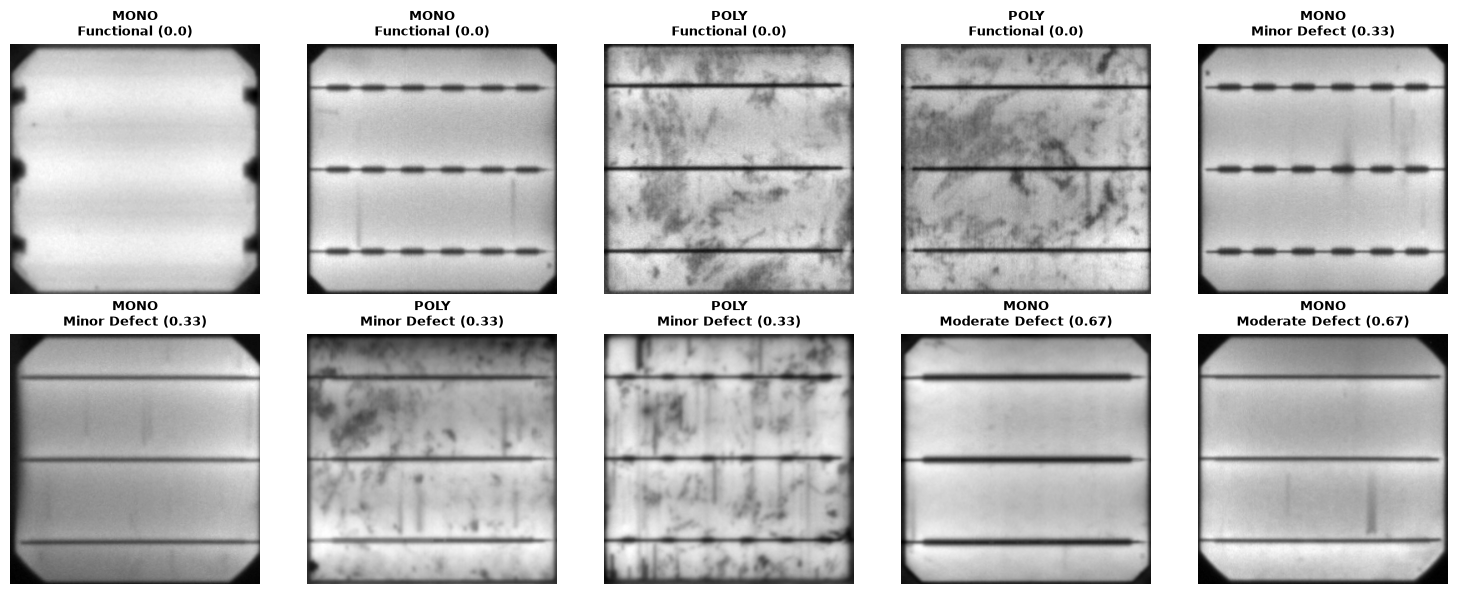

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

SRC_DIR = Path(__file__).resolve().parent if "__file__" in locals() else Path.cwd()
PROJECT_ROOT = SRC_DIR.parent if SRC_DIR.name in ["src", "notebooks"] else SRC_DIR

LABELS_PATH = PROJECT_ROOT / "data" / "labels.csv"
IMAGES_DIR = PROJECT_ROOT / "data" / "raw" / "elpv_images"

pv_labels = pd.read_csv(LABELS_PATH)
print(pv_labels.head())

# Ensuring columns are stripped of accidental leading/trailing spaces
pv_labels.columns = pv_labels.columns.str.strip()

pv_labels["full_path"] = [IMAGES_DIR / str(fname).strip() for fname in pv_labels["filename"]]

# Stratified Sampling 
sampled_groups = []
for _, group in pv_labels.groupby(["defect_prob", "wafer_type"]):
    # Sample up to 2 items per group safely
    n_samples = min(len(group), 2)
    sampled_groups.append(group.sample(n=n_samples, random_state=42))

# Combining back into a single dataframe and taking the first 10 data
samples = pd.concat(sampled_groups).head(10).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

defect_descriptions = {
    0.0: "Functional (0.0)",
    0.333: "Minor Defect (0.33)",
    0.667: "Moderate Defect (0.67)",
    1.0: "Severe / Broken (1.0)"
}

for i, (_, row) in enumerate(samples.iterrows()):
    img_path: Path = row["full_path"]
    
    if img_path.is_file():
        with Image.open(img_path) as img:
            axes[i].imshow(img.convert("L"), cmap="gray")
    else:
        axes[i].text(0.5, 0.5, f"Missing:\n{img_path.name}", 
                     ha="center", va="center", color="red", fontsize=8)

    prob_val = float(row["defect_prob"])
    prob_key = round(prob_val, 3)
    
    label_desc = defect_descriptions.get(prob_key, f"Prob: {prob_val}")
    wafer_str = str(row['wafer_type']).strip().upper()
    
    axes[i].set_title(f"{wafer_str}\n{label_desc}", fontsize=9, fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

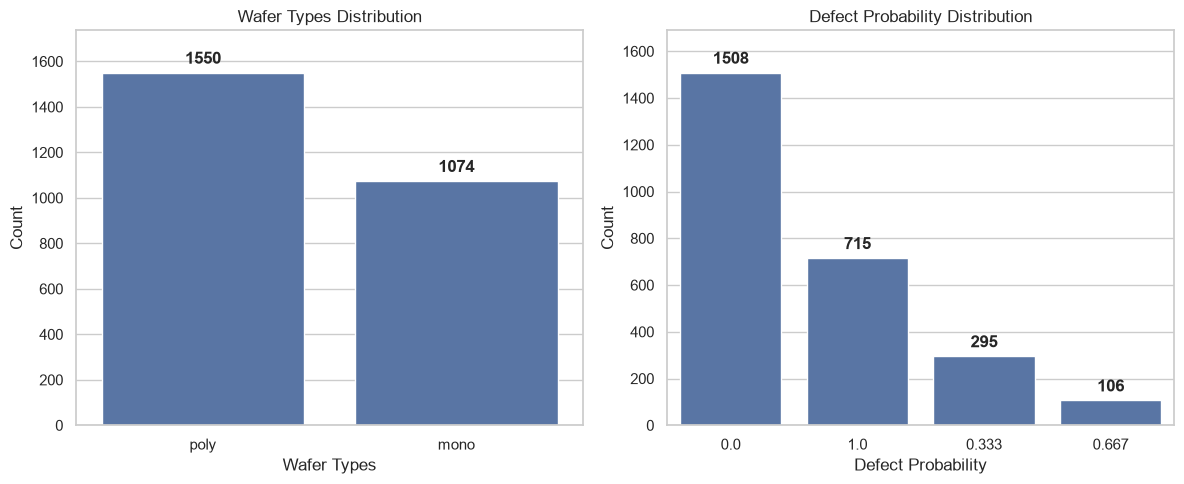

In [2]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12,5))

def plotDistributions(dataset,feature,title,i):
    plt.subplot(1,2,i)
    sns.countplot(data=dataset,
              x=feature,
              order=dataset[feature].value_counts().index)
    plt.title(f"{title} Distribution")
    plt.xlabel(title)
    plt.ylabel("Count")

    for c in plt.gca().containers:
        plt.gca().bar_label(c, padding=4, fontweight="bold")
    plt.margins(y=0.12)

plotDistributions(pv_labels,'wafer_type','Wafer Types',1)
plotDistributions(pv_labels,'defect_prob','Defect Probability',2)

plt.tight_layout()
plt.show()

* From the image we can infer that the dataset is skewed, the defect probability 0.333 and 0.667 are under represented in the dataset. 
* And defect probability 0.0 has more double samples than of the second most represented defect probability 1.0.
* To increase the variations and to make our model more robust to bias, we are generating a synthetic sensor readings from the available defect probability of the PV cells.

In [3]:
TELEMETRY_PATH = PROJECT_ROOT / "data" / "paired_telemetry.csv"
pv_telemetry = pd.read_csv(TELEMETRY_PATH)
pv_telemetry.head(10)

,filename,defect_prob,wafer_type,irradiance_w_m2,cell_temp_c,specific_power_w,specific_yield_kwh_kwp
0,cell0000.png,1.0,mono,840.8,63.10,4.766,3.093
1,cell0001.png,1.0,mono,801.4,65.45,4.361,3.189
2,cell0002.png,1.0,mono,828.4,60.21,4.623,2.410
3,cell0003.png,0.0,mono,708.4,49.92,5.624,3.674
4,cell0004.png,1.0,mono,960.1,67.40,5.071,2.840
5,cell0005.png,1.0,mono,680.8,64.70,3.695,2.287
6,cell0006.png,1.0,mono,893.5,66.14,4.696,2.437
7,cell0007.png,1.0,mono,742.3,61.80,4.176,3.000
8,cell0008.png,0.0,mono,778.2,46.08,6.263,2.526
9,cell0009.png,1.0,mono,892.6,65.08,4.788,2.232


In [4]:
pv_telemetry.groupby('defect_prob').describe().T.round(2)

defect_prob                     0.000   0.333   0.667   1.000
irradiance_w_m2        count  1508.00  295.00  106.00  715.00
                       mean    781.98  779.17  790.55  782.04
                       std     103.11  104.25   98.43   99.67
                       min     471.40  492.70  588.60  483.00
                       25%     708.88  703.70  726.30  714.55
                       50%     787.35  777.00  787.55  786.80
                       75%     862.32  864.30  864.85  856.45
                       max     998.00  992.00  983.40  992.70
cell_temp_c            count  1508.00  295.00  106.00  715.00
                       mean     48.92   52.06   57.43   63.24
                       std       4.88    4.81    4.14    4.58
                       min      33.58   37.56   48.99   46.29
                       25%      45.43   48.78   54.40   60.33
                       50%      49.04   51.81   57.48   63.48
                       75%      52.23   55.40   60.64   66.18
                       max      62.47   64.34   67.70   76.09
specific_power_w       count  1508.00  295.00  106.00  715.00
                       mean      5.92    5.52    5.01    4.13
                       std       0.74    0.68    0.61    0.49
                       min       3.37    3.75    3.64    2.62
                       25%       5.43    4.98    4.57    3.77
                       50%       5.96    5.51    5.00    4.16
                       75%       6.46    6.01    5.48    4.49
                       max       7.71    7.16    6.33    5.47
specific_yield_kwh_kwp count  1508.00  295.00  106.00  715.00
                       mean      3.43    3.32    3.02    2.53
                       std       0.91    0.87    0.81    0.68
                       min       0.99    1.30    1.28    0.73
                       25%       2.81    2.73    2.37    2.06
                       50%       3.44    3.24    2.95    2.51
                       75%       4.04    3.90    3.62    3.00
                       max       6.06    5.66    5.01    4.47

In [5]:
pv_telemetry.info()

<class 'pandas.DataFrame'>
RangeIndex: 2624 entries, 0 to 2623
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   filename                2624 non-null   str    
 1   defect_prob             2624 non-null   float64
 2   wafer_type              2624 non-null   str    
 3   irradiance_w_m2         2624 non-null   float64
 4   cell_temp_c             2624 non-null   float64
 5   specific_power_w        2624 non-null   float64
 6   specific_yield_kwh_kwp  2624 non-null   float64
dtypes: float64(5), str(2)
memory usage: 143.6 KB


* Extracting telemetry feature names. Since the Shunt Resistance is exponentially related across the degredation of wafers, using log transform of it.

In [6]:
telemetry_features = ["irradiance_w_m2", "cell_temp_c", "specific_power_w", 
"specific_yield_kwh_kwp"]

* Plotting a Corrrelation matrix (heatmap) to spot any *multicolliearity* between the features of the telemetry dataset. 

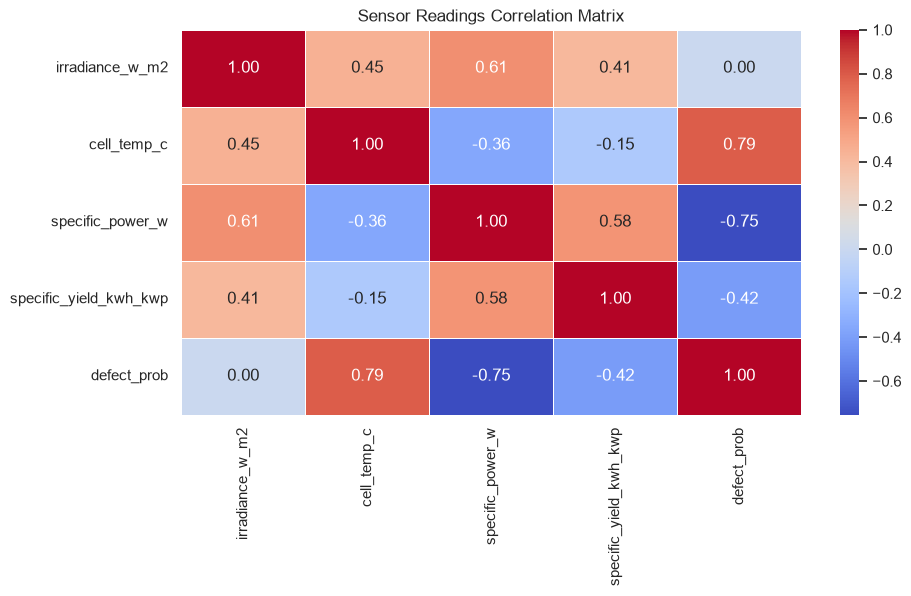

In [7]:
plt.figure(figsize=(10, 5))
corr_matrix=pv_telemetry[telemetry_features + ['defect_prob']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Sensor Readings Correlation Matrix")
plt.show()

* Plotting Violin plots to visualise the probability density of each features across different defect labels.

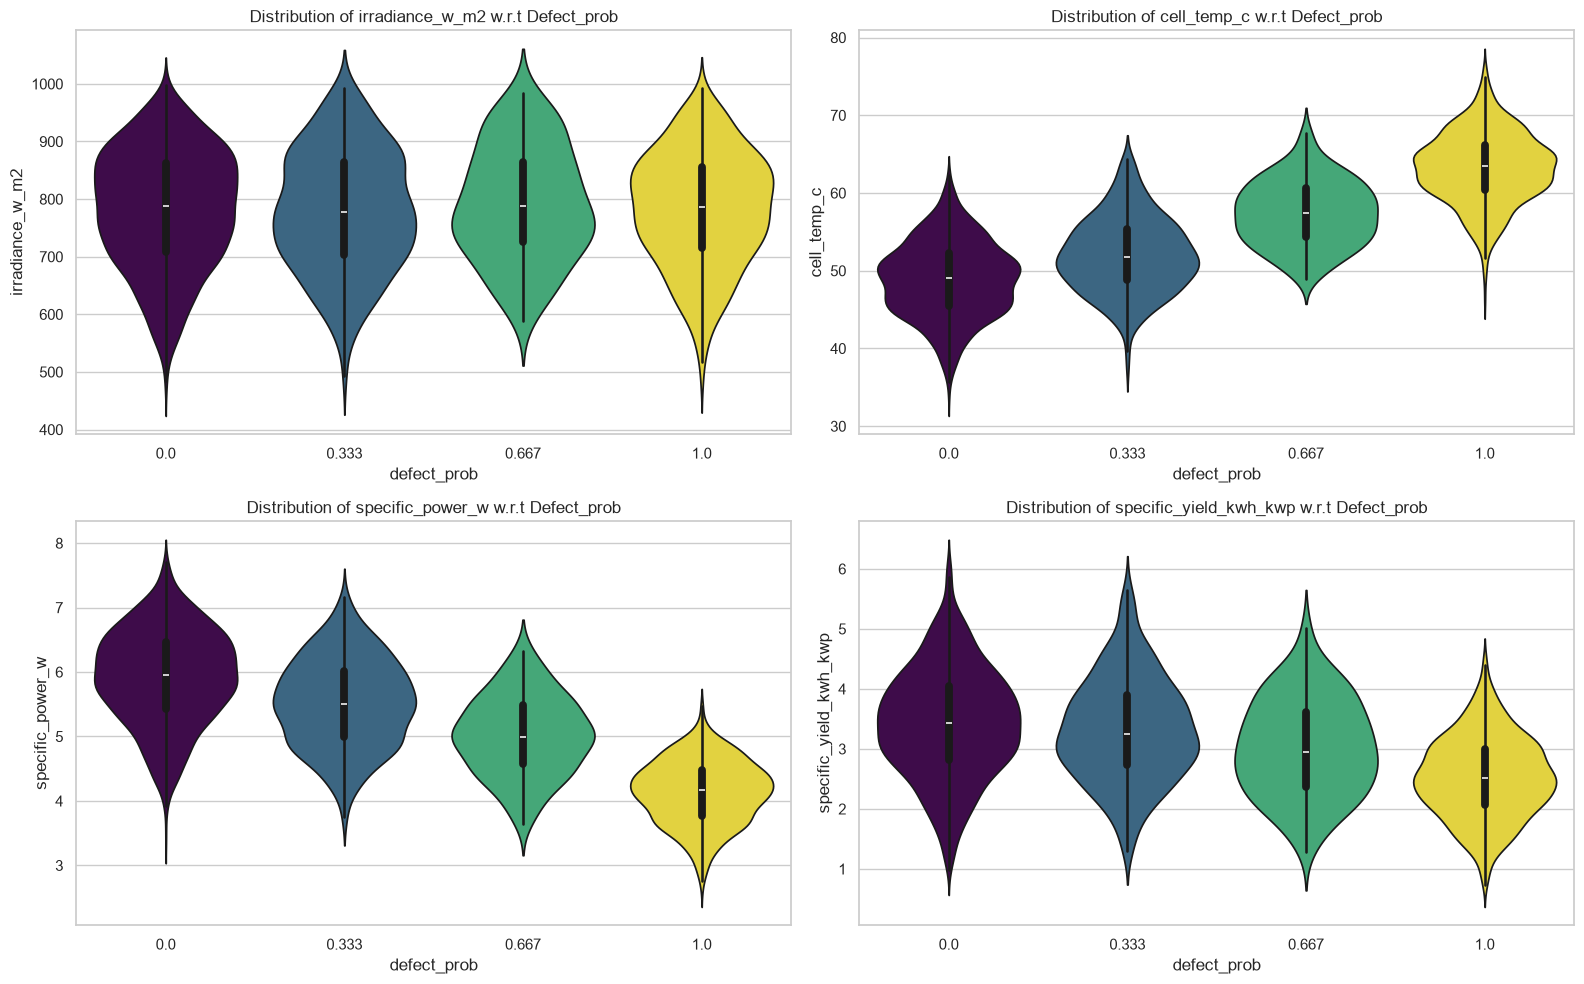

In [8]:
def plot_violins(df, features_list, target):
    # Determine the number of rows needed for subplots
    n_features = len(features_list)
    rows = (n_features + 1) // 2
    
    plt.figure(figsize=(16, 5 * rows))
    
    for i, col in enumerate(features_list):
        plt.subplot(rows, 2, i + 1)
        # We plot the feature against the Quality categories
        sns.violinplot(x=target, y=col, data=df, hue=target, palette="viridis", legend=False)
        plt.title(f"Distribution of {col} w.r.t {target.capitalize()}")
        
    plt.tight_layout()
    plt.show()

plot_violins(pv_telemetry,telemetry_features,'defect_prob')

<Figure size 1200x700 with 0 Axes>

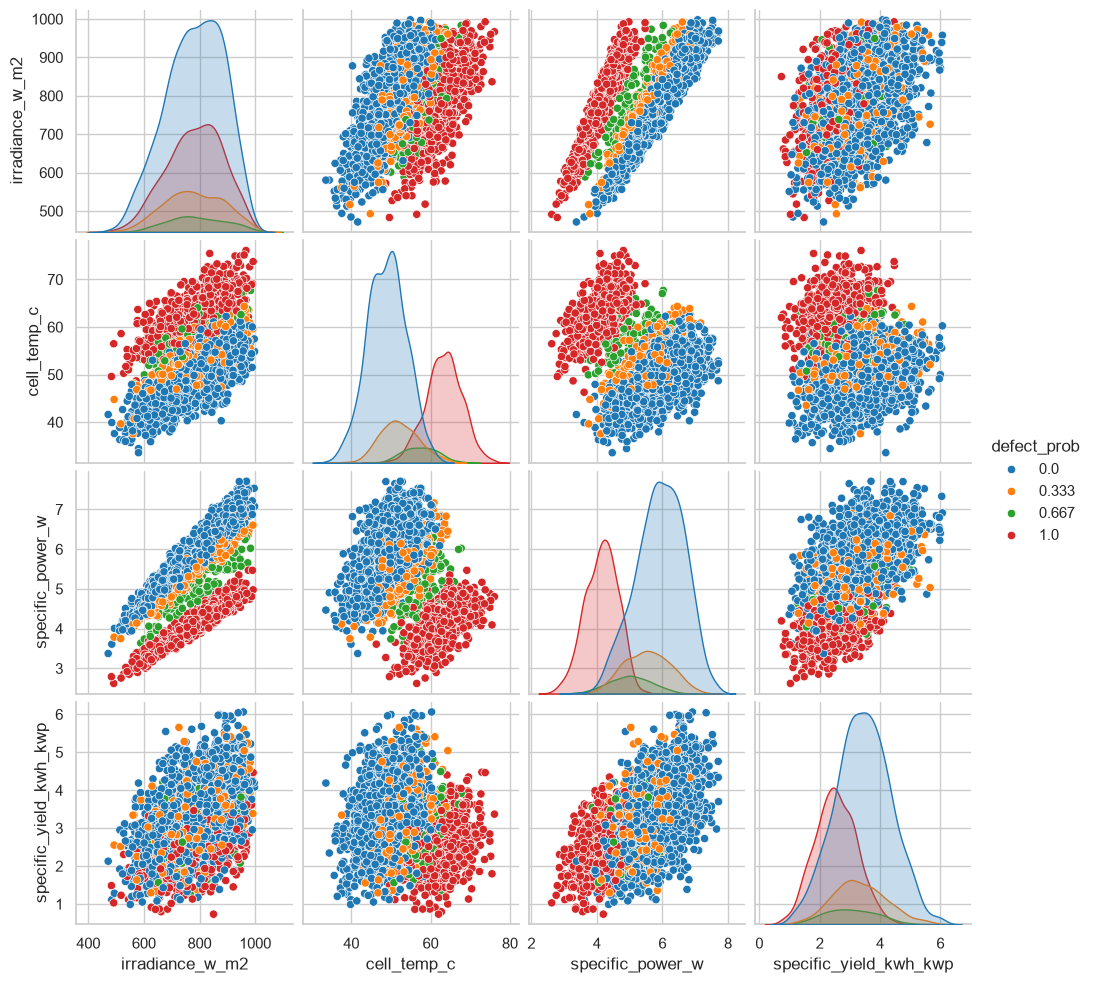

In [9]:
plt.figure(figsize=(12,7))
sns.pairplot(pv_telemetry[telemetry_features + ["defect_prob"]], hue="defect_prob", diag_kind="kde", palette="tab10")
plt.show()

* We can clearly see the interation of the sensor readings of each different features in the pairplot (scatterplot matrix).
* It provided univariate relationship of each feature as KDE plot in the diagonals and bivariate relatonship between each features pairwise as scatterplot elsewhere.
* We can clearly see the boundary amabiguity between defect probability class 0.333 and 0.667 in the scatterplots, while the 0.0 and 1.0 defect probability class cell points separates clearly relative to others.
* This will directly result in poor performance if only the sensor readings are considered for the prediction, hence requiring to be paired with the respective Electroluminescence image for making accurate predictions.

# Module-3: Data Preprocessing & Train-Test Split

* We are also performing data augmentation to increase the size of the training dataset before feeding to the model.
* We are performing all 8 types of augmentation in $D_4$ (the dihedral group of order 8).
$$\text{Group } D_4 = \{I, R_{90}, R_{180}, R_{270}, F_H, F_V, F_H \circ R_{90}, F_V \circ R_{90}\}$$
* The expected increase in dataset when performing $D_4$ augmentation is given below:

| Defect Class | Severity Meaning | Total in ELPV | Train Split (80%) | After $D_4$ Augmentation |
| --- | --- | --- | --- | --- |
| **0.0** | Functional Wafer | 1,508 (57.5%) | ~1,206 | 9,648 |
| **0.33** | Minor Defect | 295 (11.2%) | ~236 | 1,888 |
| **0.67** | Moderate Defect | 106 (4.0%) | ~85 | 680 |
| **1.0** | Severe Defect / Broken Wafer | 715 (27.3%) | ~572 | 4,576 |


In [10]:
CLASS_MAP = {0.0: 0, 0.333: 1, 0.667: 2, 1.0: 3}
pv_telemetry["image_path"] = pv_telemetry["filename"].apply(lambda fn: str(IMAGES_DIR / Path(fn).name))

# Quick sanity check on the first image path
assert Path(pv_telemetry["image_path"].iloc[0]).exists(), (f"Could not find image at: {pv_telemetry['image_path'].iloc[0]}")


def apply_exact_dihedral(img_tensor: torch.Tensor, transform_id: int) -> torch.Tensor:
    # Deterministically applies one of the 8 elements of the D4 symmetry group.
    if transform_id == 0:
        return img_tensor # Identity
    elif transform_id == 1:
        return torch.rot90(img_tensor, 1, dims=[1, 2]) # 90°
    elif transform_id == 2:
        return torch.rot90(img_tensor, 2, dims=[1, 2]) # 180°
    elif transform_id == 3:
        return torch.rot90(img_tensor, 3, dims=[1, 2]) # 270°
    elif transform_id == 4:
        return torch.flip(img_tensor, dims=[2]) # Horizontal Flip
    elif transform_id == 5:
        return torch.flip(img_tensor, dims=[1]) # Vertical Flip
    elif transform_id == 6:
        return torch.rot90(torch.flip(img_tensor, dims=[2]), 1, dims=[1, 2]) # Diagonal 1
    elif transform_id == 7:
        return torch.rot90(torch.flip(img_tensor, dims=[1]), 1, dims=[1, 2]) # Diagonal 2
    else:
        raise ValueError(f"transform_id must be in between 0 to 7, provided: {transform_id}")

In [ ]:

class MultimodalPVDataset(Dataset):
    def __init__(self, df: pd.DataFrame,scaler, is_train: bool, expand_8x: bool):
        self.df = df.reset_index(drop=True)
        self.is_train = is_train
        self.jitter_std = 0.05
        # Expanding 8x only during training
        self.expand_8x = expand_8x if is_train else False
        
        # Pre-scaling
        raw_tabular = self.df[telemetry_features].values.astype(np.float32)
        self.scaled_tabular = scaler.transform(raw_tabular).astype(np.float32)
        
        self.image_paths = self.df["image_path"].values
        self.labels = self.df["defect_prob"].round(3).map(CLASS_MAP).values.astype(np.int64)
        self.to_tensor = transforms.ToTensor()
        
        # Pre-loading all images in this split directly into RAM as tensors
        self.cached_images = [
            self.to_tensor(Image.open(p).convert("L")) for p in self.image_paths]

    def __len__(self):
        # 1,679 * 8 = 13,432 for train; 420 for val
        return len(self.df) * 8 if self.expand_8x else len(self.df)

    def __getitem__(self, idx):
        if self.expand_8x:
            base_idx = idx // 8
            transform_id = idx % 8
        else:
            base_idx = idx
            transform_id = 0

        # Fetching pre-loaded image tensor directly from RAM
        img_tensor = self.cached_images[base_idx]
        
        if self.is_train:
            img_tensor = apply_exact_dihedral(img_tensor, transform_id)

        sensor_vec = self.scaled_tabular[base_idx].copy()
        
        if self.is_train and self.jitter_std > 0.0:
            # Independently added measurement noise per orientation view
            noise = np.random.normal(0.0, self.jitter_std, size=sensor_vec.shape).astype(np.float32)
            sensor_vec = sensor_vec + noise

        sensor_tensor = torch.from_numpy(sensor_vec)
        label_tensor = torch.tensor(self.labels[base_idx], dtype=torch.long)

        return img_tensor, sensor_tensor, label_tensor

In [12]:
def prepare_splits(df: pd.DataFrame):
    # Composite key ensures both defect_prob and wafer_type (mono/poly) are balanced
    strat_key = df["defect_prob"].astype(str) + "_" + df["wafer_type"].str.lower().str.strip()

    # 80% Train, 20% Test
    train_df, test_df = train_test_split(df,test_size=0.20,random_state=42,stratify=strat_key,shuffle=True)

    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Assigning 5 Stratified Folds inside the train_df
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    train_strat_key = train_df["defect_prob"].astype(str) + "_" + train_df["wafer_type"].str.lower().str.strip()

    train_df["fold"] = -1
    for fold_idx, (_, val_idx) in enumerate(skf.split(train_df, train_strat_key)):
        train_df.loc[val_idx, "fold"] = fold_idx

    return train_df, test_df

In [13]:
def get_fold_dataloaders(train_df: pd.DataFrame, val_fold: int, batch_size: int):
    fold_train_df = train_df[train_df["fold"] != val_fold].reset_index(drop=True)
    fold_val_df   = train_df[train_df["fold"] == val_fold].reset_index(drop=True)

    # Fitting StandardScaler on the 4 training folds
    scaler = StandardScaler()
    scaler.fit(fold_train_df[telemetry_features].values.astype(np.float32))

    train_dataset = MultimodalPVDataset(fold_train_df, scaler, True, True)
    val_dataset = MultimodalPVDataset(fold_val_df, scaler, False, False)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, pin_memory=True)

    return train_loader, val_loader, scaler


def get_test_dataloader(train_df: pd.DataFrame, test_df: pd.DataFrame, batch_size: int):
    # Fit StandardScaler on the entire 80% training pool before transforming the 20% test set
    full_train_scaler = StandardScaler()
    full_train_scaler.fit(train_df[telemetry_features].values.astype(np.float32))

    test_dataset = MultimodalPVDataset(test_df,full_train_scaler,False,False)

    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)
    return test_loader, full_train_scaler

In [ ]:
train_df, test_df = prepare_splits(pv_telemetry)

print("\n5-Fold Class Distribution inside Train Set:")
print(pd.crosstab(train_df["fold"], train_df["defect_prob"]))

train_loader, val_loader, fold0_scaler = get_fold_dataloaders(train_df, val_fold=0, batch_size=32)
test_loader, full_scaler = get_test_dataloader(train_df, test_df, batch_size=32)

print(f"\nFold 0 Train Dataset Length: {len(train_loader.dataset)} ({len(train_loader)} batches)")
print(f"Fold 0 Val Dataset Length: {len(val_loader.dataset)} ({len(val_loader)} batches)")
print(f"Holdout Test Dataset Length: {len(test_loader.dataset)} ({len(test_loader)} batches)")

# 3. Verifying one batch from TrainLoader
img_batch, sensor_batch, label_batch = next(iter(train_loader))
print(f"\nBatch Shapes -> Images: {img_batch.shape}, Sensors: {sensor_batch.shape}, Labels: {label_batch.shape}")

80% Train Pool: 2099 cells | 20% Test Set: 525 cells

5-Fold Class Distribution inside Train Pool:
defect_prob  0.000  0.333  0.667  1.000
fold                                   
0              241     47     17    115
1              241     47     17    115
2              242     47     17    114
3              241     48     17    114
4              241     47     17    114

Fold 0 Train Dataset Length (8x expanded): 13432 (420 batches)
Fold 0 Val Dataset Length   (1x clean): 420 (14 batches)
Holdout Test Dataset Length (1x clean): 525 (17 batches)

Batch Shapes -> Images: torch.Size([32, 1, 300, 300]), Sensors: torch.Size([32, 4]), Labels: torch.Size([32])
